# Introduction to MRI Image Reconstruction

## Background

Medical imaging is one of the most impactful medical breakthroughs of the previous century, providing insights to clinicians for diagnostic and therapeutic purposes. Electrical engineers have been at the forefront of these breakthroughs. In particular, **magnetic resonance imaging (MRI)** has become a clinically important routine imaging modality due to its ability to visualize soft tissue.

The physics behind MRI are very elegant. Essentially, magnetic moments from water molecules are excited by radio-frequency pulses and are shaped by strong electromagnets to create a signal representative of an image inside a human body.

### The Signal Equation

From a signal processing standpoint, the signal is recorded from the scanner as:

$$s(t) = \int_\mathbb{R}\int_\mathbb{R} I(x,y)e^{-j2\pi(k_x x + k_y y)}dx dy$$

As an engineer, your job is to take this raw signal and **reconstruct** it as a usable image of the patient's anatomy. This is done through an algorithm called the **inverse Fourier transform**.

## What is k-space?

The data that we collect from the MRI scanner is called **k-space**. It is typically either representative of a 2D or 3D image, but we will focus on the 2D image (i.e., single "slice") case for this tutorial.

This k-space data has `x` and `y` dimensions (often referred to within the MRI community as $k_x$ and $k_y$). Depending on resolution needs, typical k-space dimensions will range from $128\times 128$ to $512\times 512$.

**Important:** This data is complex, meaning each data point has a real and imaginary part.

### Multi-coil Data

MRI scanners record the data with specially tuned antennas that you place around the anatomy you are interested in visualizing. To increase the scan signal-to-noise ratio, these antennas have multiple recording channels (or **coils**). Each coil is recorded individually and will produce separate k-space data.

Modern antennas will have over 32 channels. Thus, the k-space data can be thought of as a 3D array with dimensions:

$$N_\text{coils}\times N_{k_y} \times N_{k_x}$$

A typical array size might be $32\times 128 \times 128$ - though this will vary from scan to scan and which antenna is used.

## Reconstruction Pipeline Overview

The MRI reconstruction pipeline consists of several steps:

1. **Read raw k-space data** from the scanner
2. **Apply 2D Inverse FFT** to transform from k-space to image space
3. **Sum-of-squares coil combination** to combine multi-coil data
4. **FFT shift** to correct quadrant scrambling
5. **Transpose** for proper clinical viewing orientation

Let's implement each step!

## Setup: Import Required Libraries

In [57]:
import numpy as np
from matplotlib import pyplot as plt
import struct

# For better visualization
plt.rcParams["figure.figsize"] = (12, 8)
plt.rcParams["image.cmap"] = "gray"

print("Libraries imported successfully!")

Libraries imported successfully!


## Step 1: Reading P-file Data

The data file (P-file) has a specific binary format similar to General Electric MRI scanner files. It contains:
- A header with metadata about the scan
- Raw k-space data stored as 32-bit signed integers
- Complex data stored as alternating real and imaginary parts

### P-file Header Structure

| Parameter | Offset (bytes) | Data Type |
|-----------|----------------|-----------|
| Exam number | 494 | unsigned int |
| Number of coils | 1236 | unsigned short int |
| $k_y$ dimension size | 1438 | unsigned short int |
| $k_x$ dimension size | 1440 | unsigned short int |
| Header size in bytes | 1502 | unsigned int |
| k-space data size in bytes | 1510 | unsigned long int |

In [58]:
def read_pfile(filename):
    """
    Read GE binary P-file and extract k-space data

    Parameters:
    -----------
    filename : str
        Path to the P-file

    Returns:
    --------
    kspace_data : ndarray (complex128)
        3D array of shape (ncoils, ny, nx) containing complex k-space data
    metadata : dict
        Dictionary containing exam number, number of coils, and dimensions
    """
    with open(filename, "rb") as f:
        # Read header information
        f.seek(494)
        exam = struct.unpack("<I", f.read(4))[0]  # unsigned int

        f.seek(1236)
        ncoils = struct.unpack("<H", f.read(2))[0]  # unsigned short

        f.seek(1438)
        ny = struct.unpack("<H", f.read(2))[0]  # unsigned short

        f.seek(1440)
        nx = struct.unpack("<H", f.read(2))[0]  # unsigned short

        f.seek(1502)
        header_size = struct.unpack("<I", f.read(4))[0]  # unsigned int

        f.seek(1510)
        data_size = struct.unpack("<Q", f.read(8))[0]  # unsigned long int

        # Read k-space data
        f.seek(header_size)
        raw_data = np.fromfile(f, dtype=np.int32, count=data_size // 4)

    # Convert to complex: even indices are real, odd indices are imaginary
    complex_data = raw_data[::2] + 1j * raw_data[1::2]

    # Reshape to (ncoils, ny, nx)
    kspace_data = complex_data.reshape(ncoils, ny, nx)

    metadata = {
        "exam": exam,
        "ncoils": ncoils,
        "ny": ny,
        "nx": nx,
        "header_size": header_size,
        "data_size": data_size,
    }

    return kspace_data, metadata


print("read_pfile() function defined!")

read_pfile() function defined!


## Step 2: 2D Inverse Fourier Transform

The 2D inverse FFT transforms k-space data into image space. We need to:
1. Apply 1D inverse FFT to each row
2. Apply 1D inverse FFT to each column

In NumPy, we can use `np.fft.ifft2()` which does this automatically, or we can apply `np.fft.ifft()` sequentially to rows and columns.

In [59]:
def ifft_2d(kspace_data):
    """
    Apply 2D inverse FFT to k-space data

    Parameters:
    -----------
    kspace_data : ndarray (complex)
        3D array of shape (ncoils, ny, nx)

    Returns:
    --------
    image_data : ndarray (complex)
        3D array of shape (ncoils, ny, nx) in image space
    """
    ncoils = kspace_data.shape[0]
    image_data = np.zeros_like(kspace_data, dtype=complex)

    # Apply 2D inverse FFT to each coil
    for coil in range(ncoils):
        # Method 1: Using np.fft.ifft2 (easier)
        image_data[coil] = np.fft.ifft2(kspace_data[coil])

        # Method 2: Sequential 1D transforms (more explicit)
        # First transform columns (axis 0)
        # temp = np.fft.ifft(kspace_data[coil], axis=0)
        # Then transform rows (axis 1)
        # image_data[coil] = np.fft.ifft(temp, axis=1)

    return image_data


print("ifft_2d() function defined!")

ifft_2d() function defined!


## Step 3: Sum-of-Squares Coil Combination

After the inverse FFT, we have complex images from each coil. We need to combine them into a single real-valued image using the **sum-of-squares** method:

$$I(y,x) = \sqrt{\sum^{N_\text{coils}}_{n = 1} I_n(y,x) I^*_n(y,x)}$$

where $I^*_n(y,x)$ represents the complex conjugate of the image.

This is equivalent to:
$$I(y,x) = \sqrt{\sum^{N_\text{coils}}_{n = 1} |I_n(y,x)|^2}$$

In [60]:
def sum_of_squares(image_data):
    """
    Perform sum-of-squares coil combination

    Parameters:
    -----------
    image_data : ndarray (complex)
        3D array of shape (ncoils, ny, nx)

    Returns:
    --------
    combined_image : ndarray (uint8)
        2D array of shape (ny, nx) with values in [0, 255]
    """
    # Compute magnitude squared for each coil and sum
    sos = np.sqrt(np.sum(np.abs(image_data) ** 2, axis=0))

    # Scale to [0, 255] for visualization
    # Find max value and scale
    max_val = np.max(sos)
    if max_val > 0:
        scaled = (sos / max_val * 255).astype(np.uint8)
    else:
        scaled = sos.astype(np.uint8)

    return scaled


print("sum_of_squares() function defined!")

sum_of_squares() function defined!


## Step 4: FFT Shift

One artifact of the 2D FFT is that the data quadrants are shuffled. We need to swap:
- Top-left ↔ Bottom-right
- Top-right ↔ Bottom-left

Example transformation:
```
[1  2  3  4  5  6]        [16 17 18 13 14 15]
[7  8  9  10 11 12]   →   [22 23 24 19 20 21]
[13 14 15 16 17 18]       [4  5  6  1  2  3]
[19 20 21 22 23 24]       [10 11 12 7  8  9]
```

NumPy provides `np.fft.fftshift()` for this operation.

In [61]:
def ifftshift(image):
    """
    Perform FFT shift to correct quadrant scrambling

    Parameters:
    -----------
    image : ndarray
        2D array

    Returns:
    --------
    shifted_image : ndarray
        2D array with quadrants swapped
    """
    return np.fft.fftshift(image)


print("ifftshift() function defined!")

ifftshift() function defined!


## Step 5: Transpose

The final step is to transpose the image for proper clinical viewing orientation. Radiologists are very particular about how images are displayed!

In [62]:
def transpose_image(image):
    """
    Transpose the image for proper clinical viewing

    Parameters:
    -----------
    image : ndarray
        2D array

    Returns:
    --------
    transposed : ndarray
        Transposed 2D array
    """
    return image.T


print("transpose_image() function defined!")

transpose_image() function defined!


## Complete Reconstruction Pipeline

Now let's create a function that performs the entire reconstruction process and visualizes each step!

In [63]:
def reconstruct_mri(filename, visualize_steps=True):
    """
    Complete MRI reconstruction pipeline

    Parameters:
    -----------
    filename : str
        Path to P-file
    visualize_steps : bool
        Whether to visualize intermediate steps

    Returns:
    --------
    final_image : ndarray
        Reconstructed MRI image
    metadata : dict
        Scan metadata
    """
    # Step 1: Read data
    print("Step 1: Reading P-file...")
    kspace_data, metadata = read_pfile(filename)
    print(
        f"  Exam: {metadata['exam']}, Coils: {metadata['ncoils']}, "
        f"Dimensions: {metadata['ny']}x{metadata['nx']}"
    )

    # Step 2: 2D Inverse FFT
    print("Step 2: Applying 2D inverse FFT...")
    image_data = ifft_2d(kspace_data)

    # Step 3: Sum-of-squares
    print("Step 3: Sum-of-squares coil combination...")
    combined_image = sum_of_squares(image_data)

    # Step 4: FFT shift
    print("Step 4: FFT shift...")
    shifted_image = ifftshift(combined_image)

    # Step 5: Transpose
    print("Step 5: Transpose...")
    final_image = transpose_image(shifted_image)

    if visualize_steps:
        fig, axes = plt.subplots(2, 3, figsize=(15, 10))

        # k-space magnitude (log scale for visibility)
        axes[0, 0].imshow(np.log(1 + np.abs(kspace_data[0])), cmap="gray")
        axes[0, 0].set_title("Step 1: k-space (coil 0, log scale)")
        axes[0, 0].axis("off")

        # After 1D FFT (columns only) - show one coil
        temp = np.fft.ifft(kspace_data[0], axis=0)
        axes[0, 1].imshow(np.abs(temp), cmap="gray")
        axes[0, 1].set_title("Partial: After column FFT")
        axes[0, 1].axis("off")

        # After full 2D FFT - show one coil
        axes[0, 2].imshow(np.abs(image_data[0]), cmap="gray")
        axes[0, 2].set_title("Step 2: After 2D IFFT (coil 0)")
        axes[0, 2].axis("off")

        # After sum-of-squares
        axes[1, 0].imshow(combined_image, cmap="gray")
        axes[1, 0].set_title("Step 3: Sum-of-squares")
        axes[1, 0].axis("off")

        # After FFT shift
        axes[1, 1].imshow(shifted_image, cmap="gray")
        axes[1, 1].set_title("Step 4: After FFT shift")
        axes[1, 1].axis("off")

        # Final image
        axes[1, 2].imshow(final_image, cmap="gray")
        axes[1, 2].set_title("Step 5: Final (transposed)")
        axes[1, 2].axis("off")

        plt.tight_layout()
        plt.show()

    print("Reconstruction complete!")
    return final_image, metadata


print("reconstruct_mri() function defined!")

reconstruct_mri() function defined!


## Example Usage

If you have a P-file (e.g., `P26113.7`), you can run the reconstruction:

Step 1: Reading P-file...
  Exam: 2020110305, Coils: 16, Dimensions: 256x256
Step 2: Applying 2D inverse FFT...
Step 3: Sum-of-squares coil combination...
Step 4: FFT shift...
Step 5: Transpose...


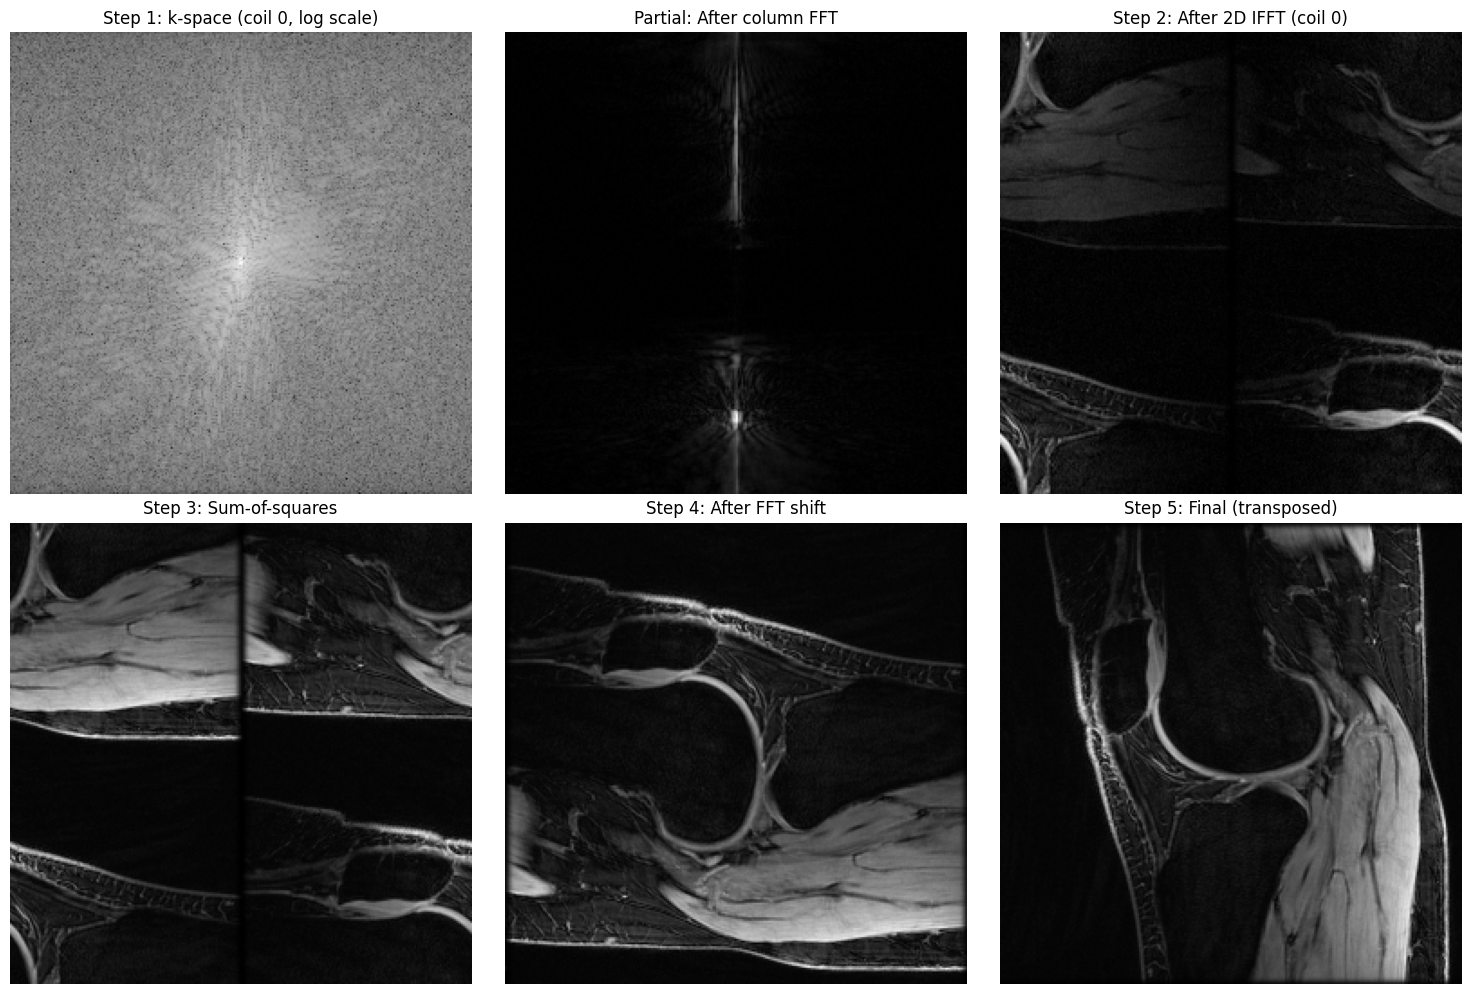

Reconstruction complete!


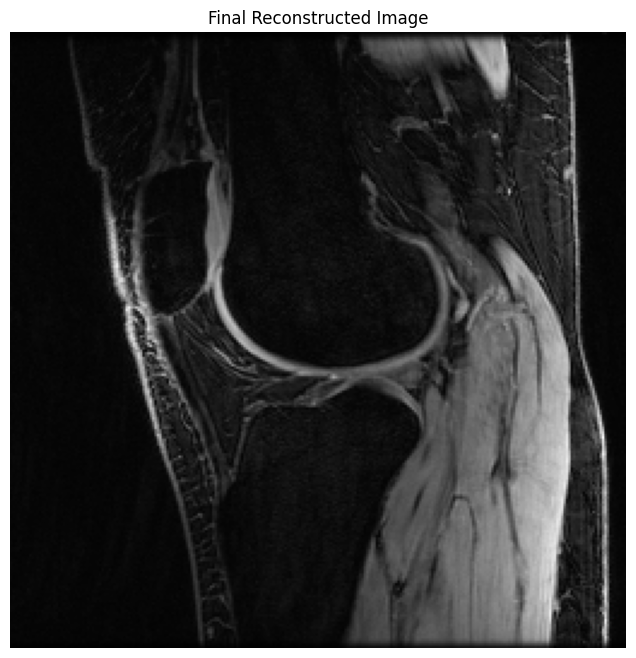

In [64]:
# Example: Run reconstruction on a P-file

pfile_path = "P26113.7"
final_image, metadata = reconstruct_mri(pfile_path, visualize_steps=True)

plt.figure()
plt.imshow(final_image)
plt.axis("off")
plt.title("Final Reconstructed Image")
plt.show()

## Undersampling Impacts

MRI is inherently slow.  Each point in $k$-space needs to be measured individually and that takes time.  There are several approaches that we can use to speed up MRI acquisition by sampling fewer points in $k$-space.

1.  We could simply not sample as far out in $k$-space.  By sampling fewer higher frequency datapoints, we are essentially low-pass filtering the image, which makes the edges of the image less sharp (which is far from ideal!).  We can see these impacts below.  We keep 25% of the original $k$-space data (you can see this in the mask image), and zero-out the rest.  We see in the $x$-direction the resulting image is blurrier. 

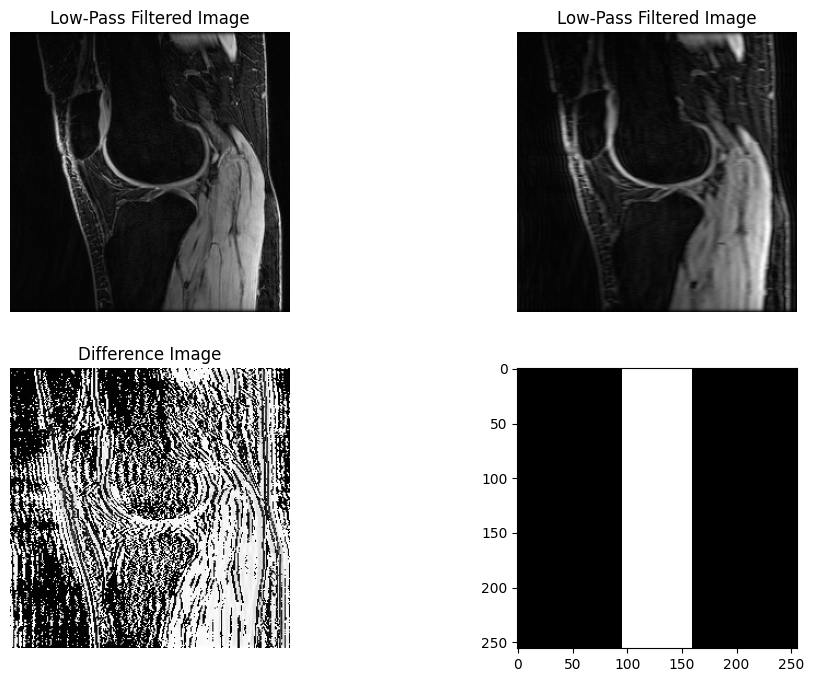

In [65]:
kspace, _ = read_pfile("P26113.7")

im_orig = np.fft.ifft2(kspace, axes=(1, 2))
im_orig_sos = sum_of_squares(im_orig)
im_orig = ifftshift(im_orig_sos).T

fc = 96
mask = np.zeros_like(kspace).real
mask[:, fc:-fc, :] = 1


kspace_lpf = kspace.copy() * mask

im_lpf = np.fft.ifft2(kspace_lpf, axes=(1, 2))
im_lpf_sos = sum_of_squares(im_lpf)
im_lpf = ifftshift(im_lpf_sos).T

diff_image = np.abs(im_orig - im_lpf)

plt.figure()


plt.subplot(221)
plt.imshow(im_orig, cmap="gray")
plt.axis("off")
plt.title("Low-Pass Filtered Image")

plt.subplot(222)
plt.imshow(im_lpf, cmap="gray")
plt.axis("off")
plt.title("Low-Pass Filtered Image")

plt.subplot(223)
plt.imshow(diff_image, cmap="gray")
plt.axis("off")
plt.title("Difference Image")

plt.subplot(224)
plt.imshow(mask[0, :, :].T.squeeze(), cmap="gray")

2.  The next approach is called parallel imaging.  Essentially, we discard every other $k$-space line (see mask image).  However, this puts our sampling rate in $k$-space below the Nyquist rate and this leads to aliasing.  The aliasing is manifest by an additional copy of the knee image which is overlaid over the image.  

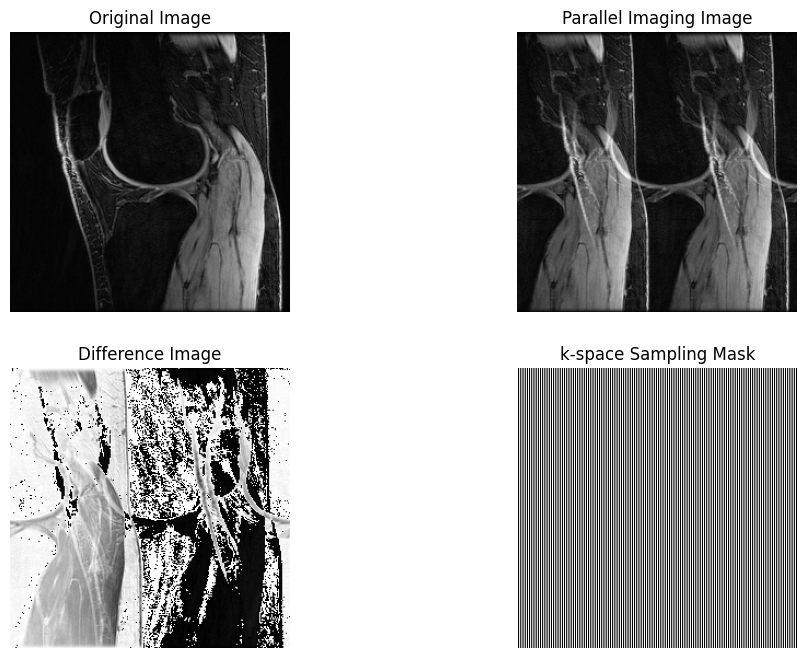

In [66]:
mask = np.zeros_like(kspace).real
mask[:, ::2, :] = 1  # Keep every other line

kspace_pi = kspace.copy() * mask
im_pi = np.fft.ifft2(kspace_pi, axes=(1, 2))
im_pi_sos = sum_of_squares(im_pi)
im_pi = ifftshift(im_pi_sos).T

plt.figure()
plt.subplot(221)
plt.imshow(im_orig, cmap="gray")
plt.axis("off")
plt.title("Original Image")
plt.subplot(222)
plt.imshow(im_pi, cmap="gray")
plt.axis("off")
plt.title("Parallel Imaging Image")
plt.subplot(223)
plt.imshow(np.abs(im_orig - im_pi), cmap="gray")
plt.axis("off")
plt.title("Difference Image")
plt.subplot(224)
plt.imshow(mask[0, :, :].T.squeeze(), cmap="gray")
plt.title("k-space Sampling Mask")
plt.axis("off")
plt.show()

3.  There are tricks to get around this aliasing artifact by leveraging redundant information in the multiple coil images.  A very common approach is called GRAPPA, which samples in the high frequency, by samples densely near the low-frequencies to create a kernel to interpolate the missing $k$-space information.

    **How GRAPPA works:**
    GRAPPA (GeneRalized Autocalibrating Partial Parallel Acquisition) is a k-space based parallel imaging method.  GRAPPA fills in the missing lines directly in k-space.
    
    *   **Autocalibration Signal (ACS):** We acquire a small region in the center of k-space fully (Nyquist sampled). This is our "ground truth" data.
    *   **Kernel Training:** We use this ACS data to learn the relationship between neighboring points across all coils. Essentially, we ask: "If I have data at points A, B, and C in coils 1-N, how do I predict the missing point D in coil 1?" This relationship is captured in a set of weights (a kernel).
    *   **Synthesis:** Once we have these weights, we go to the undersampled outer regions of k-space. We use the measured data points and the learned weights to synthesize (predict) the missing lines.
    
    This allows us to reconstruct a full k-space for each coil, which we can then transform and combine using sum-of-squares.

Running GRAPPA reconstruction...


(np.float64(-0.5), np.float64(255.5), np.float64(255.5), np.float64(-0.5))

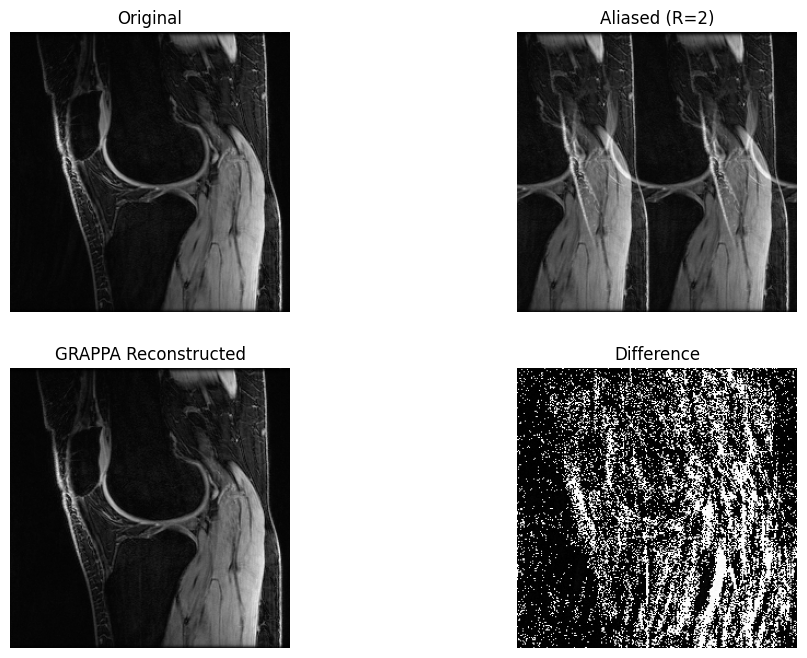

In [67]:
acs_start = 128 - 10
acs_end = 128 + 10
mask_uniform = np.zeros_like(kspace).real
mask_uniform[:, ::2, :] = 1  # Keep every other line
mask_uniform[:, acs_start:acs_end, :] = 1  # Add low-frequency lines
kspace_grappa = kspace.copy() * mask_uniform


def grappa(kspace_undersampled, acs_start=128 - 10, acs_end=128 + 10):
    """
    Simple GRAPPA implementation for R=2 undersampling.
    Assumes even lines are sampled, odd lines are missing.
    """
    ncoils, ny, nx = kspace_undersampled.shape

    # Kernel configuration: 2x3
    # We use 2 acquired lines (above and below) and 3 readout points
    # to predict the missing line in the middle.
    kernel_r = 2  # rows (acquired neighbors)
    kernel_c = 3  # columns (readout neighbors)
    pad = kernel_c // 2

    # 1. Calibration
    # Collect source (A) and target (b) data from ACS region
    # We want to predict odd lines (target) from even lines (source)

    sources = []
    targets = []

    # Iterate over ACS region, skipping borders
    for y in range(acs_start + 1, acs_end - 1):
        if y % 2 == 0:
            continue  # We only predict odd lines in calibration

        for x in range(pad, nx - pad):
            # Source: Data from all coils at neighbors
            # Neighbors: y-1 (top) and y+1 (bottom)
            # Readout: x-1, x, x+1
            src = []
            for coil in range(ncoils):
                # Top neighbor (y-1)
                src.extend(kspace_undersampled[coil, y - 1, x - pad : x + pad + 1])
                # Bottom neighbor (y+1)
                src.extend(kspace_undersampled[coil, y + 1, x - pad : x + pad + 1])
            sources.append(src)

            # Target: Data at the missing point (y, x) for all coils
            targets.append(kspace_undersampled[:, y, x])

    sources = np.array(sources)  # Shape: (N_samples, ncoils * kernel_size)
    targets = np.array(targets)  # Shape: (N_samples, ncoils)

    # Solve for weights: sources * weights = targets
    # weights = pinv(sources) * targets
    # Shape: (ncoils * kernel_size, ncoils)
    weights = np.linalg.pinv(sources) @ targets

    # 2. Reconstruction
    kspace_recon = kspace_undersampled.copy()

    # Iterate over all missing lines (odd indices)
    for y in range(1, ny - 1, 2):
        # Skip if it's in ACS (already has data), though replacing it is also fine
        # if acs_start <= y < acs_end: continue

        for x in range(pad, nx - pad):
            # Construct source vector
            src = []
            for coil in range(ncoils):
                src.extend(kspace_recon[coil, y - 1, x - pad : x + pad + 1])
                src.extend(kspace_recon[coil, y + 1, x - pad : x + pad + 1])

            src = np.array(src)

            # Predict
            prediction = src @ weights
            kspace_recon[:, y, x] = prediction

    return kspace_recon


# Run GRAPPA
print("Running GRAPPA reconstruction...")
kspace_filled = grappa(kspace_grappa)

# Reconstruct image from filled k-space
im_grappa = np.fft.ifft2(kspace_filled, axes=(1, 2))
im_grappa_sos = sum_of_squares(im_grappa)
im_grappa_final = ifftshift(im_grappa_sos).T

# Visualize
plt.figure()
plt.subplot(221)
plt.imshow(im_orig, cmap="gray")
plt.title("Original")
plt.axis("off")

plt.subplot(222)
plt.imshow(im_pi, cmap="gray")
plt.title("Aliased (R=2)")
plt.axis("off")

plt.subplot(223)
plt.imshow(im_grappa_final, cmap="gray")
plt.title("GRAPPA Reconstructed")
plt.axis("off")

plt.subplot(224)
plt.imshow(abs(im_orig - im_grappa_final), cmap="gray")
plt.title("Difference")
plt.axis("off")

4.  Starting about 15 years ago, researchers proposed a new sampling routine.  The idea was to sample _randomly_ in $k$-space, which is still sub-Nyquist sampling, but the aliasing pattern is considered to be "incoherent."  To the observer this appears to be image noise.  If we are multiplying the sampling pattern mask with the Fourier transform in the frequency domain, in the spatial domain, this is convolution with some two-dimensional impulse function $h(x,y)$, which is the inverse FFT of the mask.  Looking at this impulse functions of the uniform sampling pattern, we see two impulses.  One at the center, and another at the edge.  From a convolution perspective, this would lead to two copies of the original image.  One in the center, and one at the edge (based on the convolution shift property).  Conversely, the impulse function of the random mask, you see one dominant impulse at the center and some tapering from the center.  Convolving this impulse will give one image in the center and some noise.

Generating variable density mask (this may take a moment)...


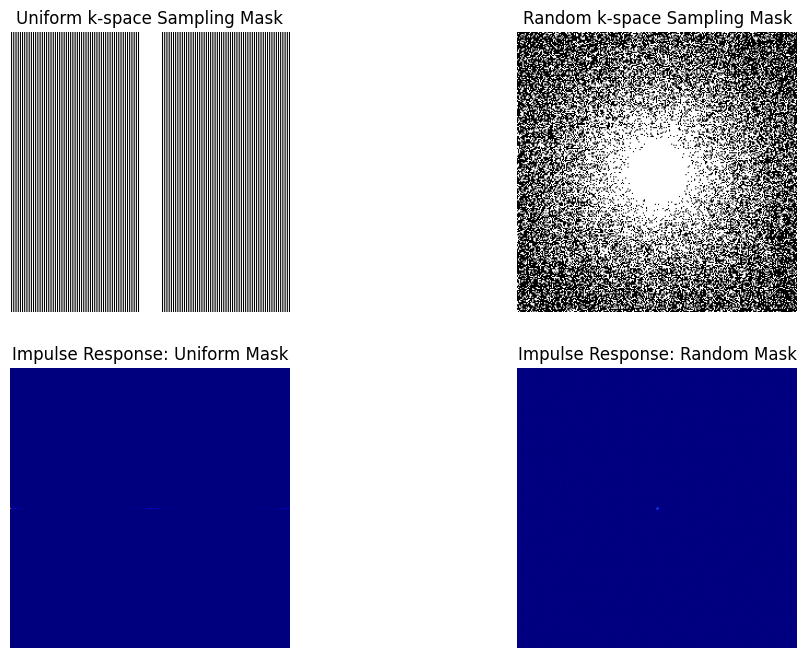

In [68]:
def get_variable_density_mask(ny, nx, R, p=2, radius=0.05, num_iters=50):
    """
    Generates a variable density sampling mask for Compressed Sensing.
    Based on Lustig et al. and the provided MATLAB code.

    Parameters:
    -----------
    ny, nx : int
        Dimensions of the mask
    R : float
        Acceleration factor (undersampling ratio)
    p : float
        Power of the polynomial decay (higher = more decay)
    radius : float
        Radius of the fully sampled center (0 to 1)
    num_iters : int
        Number of Monte Carlo iterations to find the best mask

    Returns:
    --------
    mask : ndarray
        Binary mask of shape (ny, nx)
    """
    # --- PDF Generation ---
    # Create grid
    y = np.linspace(-1, 1, ny)
    x = np.linspace(-1, 1, nx)
    X, Y = np.meshgrid(x, y)
    r = np.sqrt(X**2 + Y**2)
    r = r / np.max(r)  # Normalize to 0-1

    # Target number of samples
    num_samples = int(ny * nx / R)

    # Binary search for the optimal offset to match the target sampling rate
    min_val = 0
    max_val = 1

    pdf = np.zeros((ny, nx))

    for _ in range(100):
        val = (min_val + max_val) / 2
        pdf = (1 - r) ** p + val
        pdf[pdf > 1] = 1
        pdf[pdf < 0] = 0
        pdf[r < radius] = 1

        current_samples = np.sum(pdf)

        if abs(current_samples - num_samples) < 10:  # Tolerance
            break

        if current_samples > num_samples:
            max_val = val
        else:
            min_val = val

    # --- Mask Generation ---
    best_mask = None
    min_interference = float("inf")

    # Monte Carlo simulation to find the mask with minimal PSF side lobes
    for _ in range(num_iters):
        # Generate random mask based on PDF
        mask = np.random.random((ny, nx)) < pdf

        # Calculate PSF (Point Spread Function)
        # We want the PSF to look like a delta function (peak at center, low elsewhere)
        # The "interference" is the sum of magnitudes of off-center values

        # Weighting by 1/pdf compensates for variable density
        pdf_safe = pdf.copy()
        pdf_safe[pdf_safe == 0] = 1  # Avoid division by zero

        temp_ifft = np.fft.ifft2(mask / pdf_safe)

        # Exclude the DC component (center peak) from interference calculation
        # Note: ifft2 output is not shifted, so DC is at [0,0]
        temp_ifft_flat = temp_ifft.flatten()
        interference = np.sum(np.abs(temp_ifft_flat[1:]))

        if interference < min_interference:
            min_interference = interference
            best_mask = mask

    return best_mask.astype(float)


# Get dimensions from the kspace data
ncoils, ny, nx = kspace.shape

# Generate the mask (R=3 for good CS demonstration)
print("Generating variable density mask (this may take a moment)...")
mask_2d = get_variable_density_mask(ny, nx, R=2, p=2, radius=0.05)

# Expand to 3D for all coils
mask_random = np.tile(mask_2d[np.newaxis, :, :], (ncoils, 1, 1))

# create impulse functions for both masks
h_uniform = np.fft.fftshift(np.fft.ifft2(mask_uniform[0, :, :]))
h_random = np.fft.fftshift(np.fft.ifft2(mask_random[0, :, :]))

plt.figure()
plt.subplot(221)
plt.imshow(mask_uniform[0, :, :].T.squeeze(), cmap="gray")
plt.title("Uniform k-space Sampling Mask")
plt.axis("off")

plt.subplot(222)
plt.imshow(mask_random[0, :, :].T.squeeze(), cmap="gray")
plt.title("Random k-space Sampling Mask")
plt.axis("off")

plt.subplot(223)
plt.imshow(np.abs(h_uniform).T, cmap="jet")
plt.title("Impulse Response: Uniform Mask")
plt.axis("off")

plt.subplot(224)
plt.imshow(np.abs(h_random).T, cmap="jet")
plt.title("Impulse Response: Random Mask")
plt.axis("off")
plt.show()

Looking at the image after using this sampling pattern we see (compared to the uniform sampling).

(np.float64(-0.5), np.float64(255.5), np.float64(255.5), np.float64(-0.5))

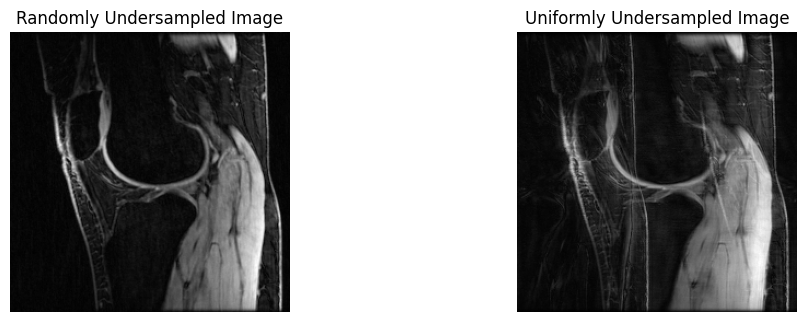

In [69]:
im_uniform = np.fft.ifft2(kspace * mask_uniform, axes=(1, 2))
im_uniform_sos = sum_of_squares(im_uniform)
im_uniform_final = ifftshift(im_uniform_sos).T

im_random = np.fft.ifft2(kspace * mask_random, axes=(1, 2))
im_random_sos = sum_of_squares(im_random)
im_random_final = ifftshift(im_random_sos).T

plt.figure()
plt.subplot(221)
plt.imshow(im_random_final, cmap="gray")
plt.title("Randomly Undersampled Image")
plt.axis("off")

plt.subplot(222)
plt.imshow(im_uniform_final, cmap="gray")
plt.title("Uniformly Undersampled Image")
plt.axis("off")

There are myriad algorithms to reconstruct these randomly undersampled datasets.  

Below is a basic implementation of a **Compressed Sensing (CS)** reconstruction algorithm.Compressed sensing relies on the idea that while a signal might look complex in one domain (like our spatial image), it might be **sparse** (mostly zeros) in another domain (like the Wavelet domain).

This algorithm uses an iterative approach called **POCS (Projection Onto Convex Sets)** to recover the missing data. Here is what is happening in the loop:

1.  **Sparsity Constraint (Denoising)**:
    *   We take our current best guess of the image and transform it into the **Wavelet domain**.
    *   We assume the "true" image should have a sparse representation here (mostly small or zero coefficients).
    *   The undersampling artifacts (which look like noise) are *not* sparse in the Wavelet domain—they are spread out everywhere.
    *   We apply **Soft Thresholding**: We shrink all the wavelet coefficients towards zero. The small coefficients (mostly noise/artifacts) get killed, while the large coefficients (real image features) survive. This effectively "denoises" the image.
    *   We transform back to the image domain.

2.  **Data Consistency**:
    *   The denoising step might have messed up the parts of the k-space we *actually measured*. We can't let that happen!
    *   We transform our denoised image back to **k-space**.
    *   We **force** the k-space values at the sampled locations to match the original raw data we collected from the scanner.
    *   We leave the *unmeasured* locations alone (keeping the values our denoising step estimated for them).

By repeating these two steps—cleaning up the image in the wavelet domain, then resetting the known k-space values—we slowly converge to an image that is both sparse (clean) and consistent with our measurements.

In practice, we are going to use more sophisticated algorithms, but those are bundled in toolboxes with somewhat complicated installations.

Starting CS reconstruction (30 iterations)...


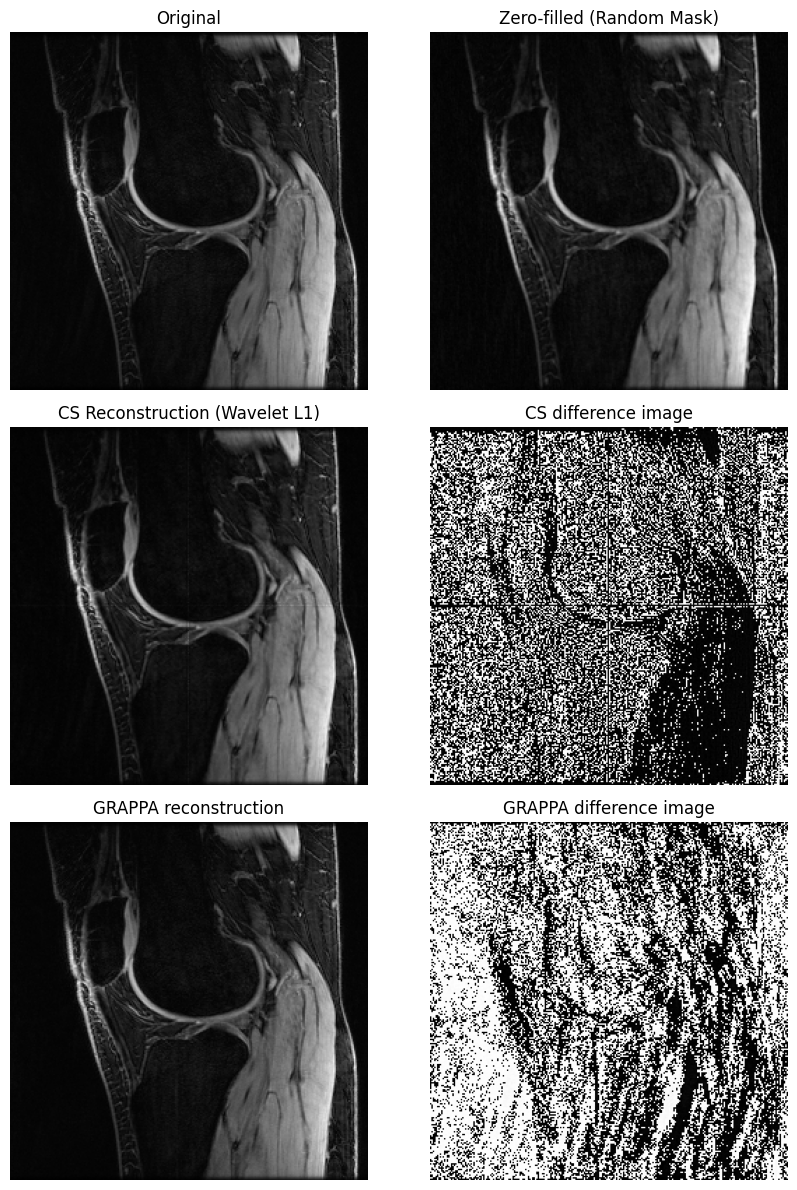

In [70]:
# Try to import PyWavelets for Wavelet Transform
try:
    import pywt
except ImportError:
    print("PyWavelets not found. Please install it using: pip install PyWavelets")
    pywt = None


def cs_reconstruction(kspace_undersampled, mask, num_iters=50, lambda_val=0.05):
    """
    Compressed Sensing Reconstruction using POCS (Projection Onto Convex Sets)
    with Wavelet Soft Thresholding.
    """
    if pywt is None:
        print("PyWavelets is required for this function.")
        return kspace_undersampled

    ncoils, ny, nx = kspace_undersampled.shape
    kspace_recon = np.zeros_like(kspace_undersampled)

    print(f"Starting CS reconstruction ({num_iters} iterations)...")

    for coil in range(ncoils):
        # Initial estimate: Zero-filled reconstruction
        x = np.fft.ifft2(kspace_undersampled[coil])

        for i in range(num_iters):
            # 1. Sparsity Constraint: Soft Thresholding in Wavelet Domain
            # We process Real and Imaginary parts separately

            def soft_thresh_coeffs(data):
                coeffs = pywt.wavedec2(data, "db4", level=2)
                # coeffs[0] is approximation (keep)
                # coeffs[1:] are details (threshold)
                new_coeffs = [coeffs[0]]
                for level in coeffs[1:]:
                    new_level = []
                    for band in level:
                        # Soft Thresholding: sign(x) * max(|x| - T, 0)
                        threshold = lambda_val * np.max(np.abs(band))
                        new_band = np.sign(band) * np.maximum(
                            np.abs(band) - threshold, 0
                        )
                        new_level.append(new_band)
                    new_coeffs.append(tuple(new_level))
                return pywt.waverec2(new_coeffs, "db4")

            x_real = soft_thresh_coeffs(x.real)
            x_imag = soft_thresh_coeffs(x.imag)

            x = x_real + 1j * x_imag

            # Fix dimensions if wavelet padding changed them
            if x.shape != (ny, nx):
                x = x[:ny, :nx]

            # 2. Data Consistency
            K_est = np.fft.fft2(x)
            # Replace acquired lines with measured data
            # mask is 1 where sampled, 0 where missing
            K_consistent = (
                K_est * (1 - mask[coil]) + kspace_undersampled[coil] * mask[coil]
            )

            x = np.fft.ifft2(K_consistent)

        kspace_recon[coil] = np.fft.fft2(x)

    return kspace_recon


# Prepare undersampled data
kspace_cs_input = kspace * mask_random

# Run CS Reconstruction
if pywt:
    kspace_cs_recon = cs_reconstruction(
        kspace_cs_input, mask_random, num_iters=30, lambda_val=0.02
    )

    # Reconstruct images
    im_cs_recon = np.fft.ifft2(kspace_cs_recon, axes=(1, 2))
    im_cs_sos = sum_of_squares(im_cs_recon)
    im_cs_final = ifftshift(im_cs_sos).T

    # Visualize in 3 rows x 2 columns
    fig, axs = plt.subplots(3, 2, figsize=(9, 12))
    axs = axs.ravel()

    imgs = [
        im_orig,
        im_random_final,
        im_cs_final,
        np.abs(im_cs_final - im_orig),
        im_grappa_final,
        np.abs(im_grappa_final - im_orig),
    ]
    titles = [
        "Original",
        "Zero-filled (Random Mask)",
        "CS Reconstruction (Wavelet L1)",
        "CS difference image",
        "GRAPPA reconstruction",
        "GRAPPA difference image",
    ]

    for ax, img, title in zip(axs, imgs, titles):
        ax.imshow(np.abs(img), cmap="gray")
        ax.set_title(title)
        ax.axis("off")

    plt.tight_layout()
    plt.show()

else:
    print("Skipping CS execution due to missing library.")